# Notebook 03 — v5: Feature Enrichment + Technical Indicators + StandardScaler

## PART A (v5): Feature Enrichment

### 10 Fitur Input

| # | Fitur | Tipe | Keterangan |
|---|---|---|---|
| 1 | `ret_close` | Harga | pct_change Close — stasioner |
| 2 | `ret_volume` | Volume | pct_change Volume — stasioner |
| 3 | `rsi_14` | Indikator | RSI-14, range 0–100, sudah stasioner |
| 4 | `macd_hist` | Indikator | MACD histogram, sudah stasioner |
| 5 | `bb_bandwidth` | Indikator | Lebar Bollinger Bands relatif, stasioner |
| 6 | `volatility_20` | Indikator | Volatilitas rolling-20, stasioner |
| 7 | `close_vs_ema20` | Indikator turunan | Close/EMA20 - 1, stasioner |
| 8 | `bb_pct_b` | Indikator turunan | Posisi Close di dalam Bollinger Band, stasioner |
| 9 | `sentiment_mean` | Sentimen | FinBERT shifted(1) hari — anti look-ahead |
| 10 | `sentiment_mean_ma3` | Sentimen | Rolling-MA3 sentimen shifted(1) — sinyal terkuat (r=0.363) |

**Catatan transform stasioner**: Semua indikator teknikal dihitung dari kolom OHLCV level
sebelum drop, lalu ditransformasi ke representasi stasioner (rasio/selisih). Semua operasi
bersifat causal (rolling/ewm ke belakang) — tidak ada look-ahead.

**Scaling**: `StandardScaler` difit HANYA pada data train (anti-leakage), kemudian
ditransformasi ke semua split (train/val/test).

---

## Konteks: Temuan Analisis Korelasi

| Fitur | Target | Pearson r | p-value | Kesimpulan |
|---|---|---|---|---|
| `sentiment_mean` | return 1-hari | 0.020 | 0.43 | **Tidak ada sinyal** |
| `sentiment_mean` | return 5-hari | 0.275 | < 0.001 | **Sinyal nyata** |
| Rolling-MA3 sentimen | return 5-hari | 0.363 | < 0.001 | **Sinyal terbaik** |

**Catatan**: Sebagian sinyal bersifat REAKTIF (berita mengikuti harga), sehingga target AUC
realistis adalah **0.55–0.60**, bukan lebih tinggi.


In [1]:
# Cell 1 — Import library dan pengaturan seed
import os
import sys
import json
import warnings
warnings.filterwarnings('ignore')

# Tambahkan root project ke sys.path agar pipeline bisa di-import
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)
from sklearn.preprocessing import StandardScaler

# Modul indikator teknikal dari pipeline project
from pipeline.feature_engineering.technical_indicators import compute_technical_indicators

# Seed untuk reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {DEVICE}')
print(f'PyTorch : {torch.__version__}')


Device  : cuda
PyTorch : 2.11.0+cu130


## 1. Load & Merge Data

Langkah-langkah:
1. Load OHLCV harian S&P500 (`GSPC_2018_2024.csv`)
2. Load sentimen harian hasil FinBERT (`headlines_daily_sentiment.csv`)
3. Left-merge sentimen ke OHLCV berdasarkan tanggal
4. **Penanganan coverage rendah** (#5): hari dengan `headline_count ≤ 2` → netralkan ke 0
5. **Perataan** (#2): hitung rolling-MA3 sentimen
6. **Anti look-ahead** (#semua sentimen): geser sentimen 1 hari ke belakang (pakai sentimen kemarin)


In [2]:
# Cell 3 — Load data, merge, rekayasa fitur sentimen

BASE_DIR = os.path.join(os.path.dirname(os.path.abspath('.')), 'stock_prediction')
# Path relatif terhadap direktori notebook
OHLCV_PATH     = '../data/raw/stocks/GSPC_2018_2024.csv'
SENTIMENT_PATH = '../data/processed/sentiment/headlines_daily_sentiment.csv'

# --- 1. Load OHLCV ---
df_price = pd.read_csv(OHLCV_PATH, parse_dates=['Date'])
df_price = df_price.sort_values('Date').reset_index(drop=True)
# Hapus kolom yang tidak relevan untuk model
df_price = df_price.drop(columns=['Dividends', 'Stock Splits'], errors='ignore')

# --- 2. Load sentimen ---
df_sent = pd.read_csv(SENTIMENT_PATH, parse_dates=['Date'])
# Hanya kolom yang berguna berdasarkan analisis korelasi
df_sent = df_sent[['Date', 'sentiment_mean', 'sentiment_neg', 'headline_count']].copy()

# --- 3. Merge (left join agar semua hari OHLCV tetap ada) ---
df = df_price.merge(df_sent, on='Date', how='left')

# --- 4. Penanganan coverage rendah (#5) ---
# Hari dengan sedikit headline → sentimen tidak andal → netralkan
low_coverage_mask = df['headline_count'].fillna(0) <= 2
df.loc[low_coverage_mask, 'sentiment_mean'] = 0.0
df.loc[low_coverage_mask, 'sentiment_neg']  = 0.0
print(f'Hari dengan coverage rendah (headline_count ≤ 2): {low_coverage_mask.sum()}')

# Isi NaN sisa (hari tanpa baris sentimen sama sekali) dengan 0.0
df['sentiment_mean'] = df['sentiment_mean'].fillna(0.0)
df['sentiment_neg']  = df['sentiment_neg'].fillna(0.0)

# --- 5. Rolling-MA3 sentimen (#2) ---
# Dihitung sebelum shift agar smoothing berbasis data aktual (bukan shifted)
df['sentiment_mean_ma3'] = df['sentiment_mean'].rolling(3, min_periods=1).mean()

# --- 6. Anti look-ahead: geser semua sentimen 1 hari (#all) ---
# Dengan shift(1), pada hari t kita hanya 'melihat' sentimen hari t-1
df['sentiment_mean']     = df['sentiment_mean'].shift(1)
df['sentiment_neg']      = df['sentiment_neg'].shift(1)
df['sentiment_mean_ma3'] = df['sentiment_mean_ma3'].shift(1)

print(f'Shape setelah merge: {df.shape}')
print(f'Kolom: {df.columns.tolist()}')
print(f'Rentang tanggal: {df["Date"].min().date()} — {df["Date"].max().date()}')
df.head()


Hari dengan coverage rendah (headline_count ≤ 2): 253
Shape setelah merge: (1552, 10)
Kolom: ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'sentiment_mean', 'sentiment_neg', 'headline_count', 'sentiment_mean_ma3']
Rentang tanggal: 2018-01-02 — 2024-03-04


,Date,Open,High,Low,Close,Volume,sentiment_mean,sentiment_neg,headline_count,sentiment_mean_ma3
0,2018-01-02,2683.729980,2695.889893,2682.360107,2695.810059,3397430000,NaN,NaN,9.0,NaN
1,2018-01-03,2697.850098,2714.370117,2697.770020,2713.060059,3544030000,0.311223,0.111111,6.0,0.311223
2,2018-01-04,2719.310059,2729.290039,2719.070068,2723.989990,3697340000,-0.018505,0.333333,2.0,0.146359
3,2018-01-05,2731.330078,2743.449951,2727.919922,2743.149902,3239280000,0.000000,0.000000,2.0,0.097573
4,2018-01-08,2742.669922,2748.510010,2737.600098,2747.709961,3246160000,0.000000,0.000000,6.0,-0.006168


In [3]:
# Cell 4 — Hitung indikator teknikal, transform stasioner, bersihkan kolom
#
# URUTAN WAJIB:
#   a) Hitung indikator teknikal DARI kolom OHLCV level (sebelum di-drop)
#   b) Buat Close_raw (untuk target di Cell 5)
#   c) Bangun fitur stasioner turunan indikator
#   d) Buat ret_close & ret_volume (pct_change)
#   e) Drop kolom level & indikator level yang tidak dipakai sebagai fitur
#   f) Buang baris NaN warmup indikator
#
# Catatan: indikator turunan harga (close_vs_ema20, bb_pct_b, dll.) dinyatakan
# dalam bentuk stasioner (rasio/selisih terhadap moving average) — bukan level
# harga mentah. Semua operasi bersifat causal (rolling/ewm ke belakang, tidak
# ada look-ahead).

# --- a) Hitung indikator teknikal dari OHLCV level ---
# compute_technical_indicators butuh kolom: Date, Open, High, Low, Close, Volume
# Semua kolom ini masih ada dari hasil merge Cell 3.
# Fungsi mengurutkan by Date & reset_index — aman dipakai di sini.
df = compute_technical_indicators(df)
# Kolom baru yang dihasilkan:
# ema_20, ema_50, rsi_14, macd, macd_signal, macd_hist,
# bb_mid, bb_upper, bb_lower, bb_bandwidth, daily_return, volatility_20

# --- b) Simpan Close asli untuk membangun target di Cell 5 ---
# Dibuat SETELAH compute agar tidak terpengaruh reorder di dalam fungsi
df['Close_raw'] = df['Close'].copy()

# --- c) Fitur stasioner turunan indikator ---
# close_vs_ema20: posisi Close relatif terhadap EMA-20 (stasioner)
df['close_vs_ema20'] = df['Close'] / df['ema_20'] - 1
# bb_pct_b: posisi Close dalam Bollinger Band (0=lower, 1=upper; stasioner)
df['bb_pct_b'] = (df['Close'] - df['bb_lower']) / (df['bb_upper'] - df['bb_lower'])
# rsi_14, macd_hist, bb_bandwidth, volatility_20 sudah stasioner — pakai langsung

# --- d) Return persentase untuk Close dan Volume ---
df['ret_close']  = df['Close'].pct_change()
df['ret_volume'] = df['Volume'].pct_change()
# ret_open/high/low tidak dipakai lagi (redundan, ret_close cukup representatif)

# --- e) Drop kolom level & indikator level yang tidak dipakai sebagai fitur ---
# Dipertahankan: Date, Close_raw, sentiment_mean, sentiment_mean_ma3,
#                ret_close, ret_volume, rsi_14, macd_hist, bb_bandwidth,
#                volatility_20, close_vs_ema20, bb_pct_b
cols_to_drop = [
    'Open', 'High', 'Low', 'Close', 'Volume',  # level OHLCV
    'ema_20', 'ema_50',                          # level MA (dipakai untuk turunan, bukan fitur)
    'macd', 'macd_signal',                       # level MACD (macd_hist sudah stasioner)
    'bb_mid', 'bb_upper', 'bb_lower',            # level BB (bb_bandwidth & bb_pct_b sudah stasioner)
    'daily_return',                              # duplikat ret_close (sama-sama pct_change Close)
    'headline_count',                            # noise — MI lemah
    'sentiment_neg',                             # dihapus v5 (fitur berkurang dari 8 → 10 stasioner)
]
df = df.drop(columns=cols_to_drop, errors='ignore')

# --- f) Buang baris NaN dari warmup indikator (ema_50 perlu 50 baris, bb perlu 20, dll.) ---
# Kolom non-sentimen baru yang perlu lengkap sebelum melanjutkan:
FEATURE_COLS_PARTIAL = [
    'ret_close', 'ret_volume', 'rsi_14', 'macd_hist',
    'bb_bandwidth', 'volatility_20', 'close_vs_ema20', 'bb_pct_b',
    'sentiment_mean',
]
# Ganti inf -> NaN sebelum dropna (mis. ret_volume = pct_change dari Volume=0,
# atau pembagian bb_pct_b saat band sangat sempit). dropna TIDAK membuang inf.
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=FEATURE_COLS_PARTIAL).reset_index(drop=True)

print(f'Shape setelah enrichment indikator teknikal: {df.shape}')
print(f'Kolom: {df.columns.tolist()}')
df.describe()


Shape setelah enrichment indikator teknikal: (1531, 12)
Kolom: ['Date', 'sentiment_mean', 'sentiment_mean_ma3', 'rsi_14', 'macd_hist', 'bb_bandwidth', 'volatility_20', 'Close_raw', 'close_vs_ema20', 'bb_pct_b', 'ret_close', 'ret_volume']


,Date,sentiment_mean,sentiment_mean_ma3,rsi_14,macd_hist,bb_bandwidth,volatility_20,Close_raw,close_vs_ema20,bb_pct_b,ret_close,ret_volume
count,1531,1531.000000,1531.000000,1531.000000,1531.000000,1531.000000,1531.000000,1531.000000,1531.000000,1531.000000,1531.000000,1531.000000
mean,2021-02-13 19:17:49.888961,-0.052165,-0.052251,55.015288,0.081482,0.071433,0.010786,3635.286786,0.003609,0.601864,0.000469,0.014415
min,2018-01-31 00:00:00,-0.829966,-0.655740,17.658277,-61.221101,0.020270,0.003139,2237.399902,-0.182984,-0.455268,-0.119841,-1.000000
25%,2019-08-08 12:00:00,-0.192653,-0.149404,46.719035,-6.838068,0.043809,0.006470,2907.234985,-0.006779,0.360952,-0.004921,-0.067655
50%,2021-02-16 00:00:00,0.000000,-0.045145,56.656841,0.848007,0.059525,0.009048,3756.070068,0.009092,0.697347,0.000819,-0.005793
75%,2022-08-22 12:00:00,0.058389,0.050651,63.835303,6.806230,0.083751,0.013145,4273.659912,0.018143,0.862784,0.006887,0.078670
max,2024-03-04 00:00:00,0.653321,0.407922,82.900410,60.895804,0.433531,0.061182,5137.080078,0.067591,1.234650,0.093828,1.270527
std,NaN,0.228431,0.151729,11.481839,13.965321,0.048289,0.007314,714.529484,0.024282,0.325851,0.012962,0.182885


In [4]:
# Cell 5 — Bangun target: arah 5-hari ke depan (#1 & #6)

HORIZON   = 5     # prediksi 5 hari ke depan (bukan 1 hari)
THRESHOLD = 0.01  # filter zona netral ±1% (#6)

# Forward return 5-hari (anti look-ahead: shift(-HORIZON))
df['fwd_ret'] = df['Close_raw'].pct_change(HORIZON).shift(-HORIZON)

before_filter = len(df)
# Filter zona netral: hanya pertahankan hari dengan gerakan > 1%
df = df[df['fwd_ret'].abs() >= THRESHOLD].copy()
after_filter = len(df)

# Label biner: 1 = naik, 0 = turun
df['target'] = (df['fwd_ret'] > 0).astype(int)

# Hapus kolom helper
df = df.drop(columns=['Close_raw', 'fwd_ret'])
df = df.dropna().reset_index(drop=True)

print(f'Baris sebelum filter threshold: {before_filter}')
print(f'Baris setelah filter threshold: {after_filter}')
print(f'Baris setelah dropna final    : {len(df)}')
print()
vc = df['target'].value_counts()
print(f'Distribusi target:')
print(f'  Up   (1): {vc.get(1,0)} ({vc.get(1,0)/len(df)*100:.1f}%)')
print(f'  Down (0): {vc.get(0,0)} ({vc.get(0,0)/len(df)*100:.1f}%)')


Baris sebelum filter threshold: 1531
Baris setelah filter threshold: 962
Baris setelah dropna final    : 962

Distribusi target:
  Up   (1): 594 (61.7%)
  Down (0): 368 (38.3%)


## 2. Fitur & Urutan (Sequences)

### Pilihan Fitur v5 (10 fitur — enrichment indikator teknikal stasioner)

| # | Fitur | Tipe | Alasan Dimasukkan |
|---|---|---|---|
| 1 | `ret_close` | OHLCV (pct_change) | Dinamika harga stasioner — sinyal utama |
| 2 | `ret_volume` | OHLCV (pct_change) | Volume momentum stasioner |
| 3 | `rsi_14` | Indikator teknikal | Oversold/overbought; sudah bounded 0–100 |
| 4 | `macd_hist` | Indikator teknikal | Momentum selisih EMA; stasioner |
| 5 | `bb_bandwidth` | Indikator teknikal | Volatilitas regime; stasioner |
| 6 | `volatility_20` | Indikator teknikal | Volatilitas rolling; stasioner |
| 7 | `close_vs_ema20` | Indikator turunan | Tren jangka pendek (Close/EMA20 - 1); stasioner |
| 8 | `bb_pct_b` | Indikator turunan | Posisi dalam band; stasioner |
| 9 | `sentiment_mean` | Sentimen | r=0.275 dengan return 5-hari |
| 10 | `sentiment_mean_ma3` | Sentimen halus | MA3 memberi r=0.363 — fitur sentimen terkuat |

**DIHAPUS** dari v4: `ret_open`, `ret_high`, `ret_low` (redundan dengan `ret_close`),
`sentiment_neg` (korelasi lemah di horizon 5-hari).

**DITAMBAH** di v5: 8 fitur indikator teknikal stasioner.

Total: **10 fitur**, WINDOW_SIZE=20 hari. Semua fitur dinormalisasi via `StandardScaler`
yang difit hanya pada data train (anti-leakage).


In [5]:
# Cell 7 — Definisi fitur, pembangunan urutan, scaling anti-leakage, dan pembagian data

# 10 fitur v5: 8 indikator teknikal stasioner + 2 sentimen
FEATURE_COLS = [
    'ret_close',
    'ret_volume',
    'rsi_14',
    'macd_hist',
    'bb_bandwidth',
    'volatility_20',
    'close_vs_ema20',
    'bb_pct_b',
    'sentiment_mean',
    'sentiment_mean_ma3',
]

WINDOW_SIZE = 20  # panjang urutan look-back default


def build_sequences(df, window, feature_cols, target_col='target'):
    """Bangun urutan sliding window (X, y, dates) dari DataFrame.

    Args:
        df          : DataFrame yang sudah bersih & terurut berdasarkan tanggal
        window      : Panjang look-back (jumlah hari per sampel)
        feature_cols: Nama kolom fitur
        target_col  : Nama kolom target

    Returns:
        X     : np.ndarray shape (N, window, n_features)
        y     : np.ndarray shape (N,)
        dates : np.ndarray tanggal prediksi (hari terakhir tiap window)
    """
    X_list, y_list, date_list = [], [], []
    feat = df[feature_cols].values
    tgt  = df[target_col].values
    dates = df['Date'].values

    for i in range(window, len(df)):
        X_list.append(feat[i - window:i])
        y_list.append(tgt[i])
        date_list.append(dates[i])

    return (
        np.array(X_list, dtype=np.float32),
        np.array(y_list, dtype=np.int64),
        np.array(date_list),
    )


def scale_sequences(X_tr, X_vl, X_te):
    """Fit StandardScaler pada data TRAIN saja (anti-leakage), transform semua split.

    Catatan: helper ini dipakai ulang oleh tahap grid search / eval / walk-forward
    (fit pada train tiap split) untuk menjaga anti-leakage secara konsisten.
    Scaler di-fit pada X_tr.reshape(-1, n_feat) agar setiap fitur dinormalisasi
    berdasarkan distribusi train saja.

    Args:
        X_tr : np.ndarray shape (N_train, window, n_features)
        X_vl : np.ndarray shape (N_val,   window, n_features)
        X_te : np.ndarray shape (N_test,  window, n_features)

    Returns:
        X_tr_scaled, X_vl_scaled, X_te_scaled : array yang sudah di-scale
        scaler                                 : StandardScaler yang sudah difit
    """
    n_feat = X_tr.shape[2]
    scaler = StandardScaler().fit(X_tr.reshape(-1, n_feat))

    def _tf(X):
        if len(X) == 0:
            return X
        return scaler.transform(X.reshape(-1, n_feat)).reshape(X.shape).astype(np.float32)

    return _tf(X_tr), _tf(X_vl), _tf(X_te), scaler


X_all, y_all, dates_all = build_sequences(df, WINDOW_SIZE, FEATURE_COLS)
N = len(X_all)

# Pembagian kronologis 70 / 15 / 15
train_end = int(N * 0.70)
val_end   = int(N * 0.85)

X_train, y_train = X_all[:train_end], y_all[:train_end]
X_val,   y_val   = X_all[train_end:val_end], y_all[train_end:val_end]
X_test,  y_test  = X_all[val_end:], y_all[val_end:]

dates_train = dates_all[:train_end]
dates_val   = dates_all[train_end:val_end]
dates_test  = dates_all[val_end:]

# --- Scaling anti-leakage: fit StandardScaler HANYA pada X_train ---
X_train, X_val, X_test, feature_scaler = scale_sequences(X_train, X_val, X_test)

print(f'Total sampel    : {N}')
print(f'Train  : {X_train.shape}  [{pd.Timestamp(dates_train[0]).date()} — {pd.Timestamp(dates_train[-1]).date()}]')
print(f'Val    : {X_val.shape}  [{pd.Timestamp(dates_val[0]).date()} — {pd.Timestamp(dates_val[-1]).date()}]')
print(f'Test   : {X_test.shape}  [{pd.Timestamp(dates_test[0]).date()} — {pd.Timestamp(dates_test[-1]).date()}]')
print()
print(f'Up% Train: {y_train.mean()*100:.1f}%  Val: {y_val.mean()*100:.1f}%  Test: {y_test.mean()*100:.1f}%')
print(f'Fitur    : {len(FEATURE_COLS)} — {FEATURE_COLS}')


Total sampel    : 942
Train  : (659, 20, 10)  [2018-03-15 — 2022-05-20]
Val    : (141, 20, 10)  [2022-05-23 — 2023-03-03]
Test   : (142, 20, 10)  [2023-03-06 — 2024-02-26]

Up% Train: 61.9%  Val: 54.6%  Test: 69.7%
Fitur    : 10 — ['ret_close', 'ret_volume', 'rsi_14', 'macd_hist', 'bb_bandwidth', 'volatility_20', 'close_vs_ema20', 'bb_pct_b', 'sentiment_mean', 'sentiment_mean_ma3']


In [6]:
# Cell 8 — Dataset PyTorch & DataLoader

BATCH_SIZE = 32


class StockDataset(Dataset):
    """Dataset urutan saham untuk klasifikasi arah harga."""

    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# Loader — shuffle=False untuk menjaga urutan kronologis
# (tidak memakai class weight karena threshold ±1% sudah menyeimbangkan kelas)
train_loader = DataLoader(StockDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=False)
val_loader   = DataLoader(StockDataset(X_val,   y_val),   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(StockDataset(X_test,  y_test),  batch_size=BATCH_SIZE, shuffle=False)

print(f'Batch train : {len(train_loader)}')
print(f'Batch val   : {len(val_loader)}')
print(f'Batch test  : {len(test_loader)}')
print()
vc_train = pd.Series(y_train).value_counts().sort_index()
print('Distribusi kelas di train set:')
print(f'  Down (0): {vc_train.get(0,0)}  Up (1): {vc_train.get(1,0)}')


Batch train : 21
Batch val   : 5
Batch test  : 5

Distribusi kelas di train set:
  Down (0): 251  Up (1): 408


## 3. Arsitektur LSTM

Desain menggunakan **mean-pooling** seluruh output time-step (bukan hanya hidden state terakhir)
untuk menangkap informasi dari sepanjang jendela look-back, bukan hanya titik terakhir.

```
Input (batch, window, 8)
  └─► nn.LSTM  → output (batch, window, hidden)
         └─► .mean(dim=1)          # rata-rata seluruh time-step
              └─► nn.Dropout
                   └─► nn.Linear(hidden, 2)  # logit Down / Up
```


In [7]:
# Cell 10 — Definisi arsitektur LSTMClassifier

class LSTMClassifier(nn.Module):
    """Klasifikasi arah harga dengan LSTM + mean-pooling.

    Args:
        input_size  : Jumlah fitur input (10 untuk v5)
        hidden_size : Ukuran hidden state LSTM (default 32 — kapasitas kecil, anti-overfit)
        num_layers  : Jumlah layer LSTM yang ditumpuk (default 1)
        dropout     : Dropout di FC layer setelah mean-pooling (default 0.5)
        num_classes : Jumlah kelas output (2: Down / Up)
    """

    def __init__(
        self,
        input_size: int,
        hidden_size: int = 32,
        num_layers: int = 1,
        dropout: float = 0.5,
        num_classes: int = 2,
    ):
        super().__init__()
        # dropout di dalam LSTM hanya aktif jika num_layers > 1
        lstm_dropout = dropout if num_layers > 1 else 0.0
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
        )
        self.dropout = nn.Dropout(dropout)
        self.fc      = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x : (batch, window, input_size)
        out, _ = self.lstm(x)            # (batch, window, hidden_size)
        pooled = out.mean(dim=1)         # mean-pooling → (batch, hidden_size)
        pooled = self.dropout(pooled)
        logits = self.fc(pooled)         # (batch, num_classes)
        return logits


INPUT_SIZE = len(FEATURE_COLS)  # 10

# Demo model dengan default baru: hidden=32, layers=1, dropout=0.5
_demo = LSTMClassifier(input_size=INPUT_SIZE)
n_params = sum(p.numel() for p in _demo.parameters() if p.requires_grad)
print(_demo)
print(f'\nDefault: hidden_size=32, num_layers=1, dropout=0.5')
print(f'Jumlah parameter yang dapat dilatih: {n_params:,}')


LSTMClassifier(
  (lstm): LSTM(10, 32, batch_first=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=32, out_features=2, bias=True)
)

Default: hidden_size=32, num_layers=1, dropout=0.5
Jumlah parameter yang dapat dilatih: 5,698


In [8]:
# Cell 11 — Fungsi bantu: train_epoch, evaluate, train_one, ensemble_predict


def train_epoch(model, loader, optimizer, criterion, device):
    """Satu epoch pelatihan. Mengembalikan (loss_rata2, akurasi)."""
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss   = criterion(logits, y_batch)
        loss.backward()
        # Gradient clipping untuk stabilitas pelatihan
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * len(y_batch)
        preds       = logits.argmax(dim=1)
        correct    += (preds == y_batch).sum().item()
        total      += len(y_batch)

    return total_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    """Evaluasi model. Mengembalikan (loss, akurasi, auc)."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_labels, all_probs = [], []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss   = criterion(logits, y_batch)

            total_loss += loss.item() * len(y_batch)
            preds       = logits.argmax(dim=1)
            correct    += (preds == y_batch).sum().item()
            total      += len(y_batch)

            probs = torch.softmax(logits, dim=1)[:, 1]
            all_labels.extend(y_batch.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    avg_loss = total_loss / total
    acc      = correct / total
    try:
        auc = roc_auc_score(all_labels, all_probs)
    except ValueError:
        # Terjadi jika hanya ada satu kelas dalam batch
        auc = 0.5

    return avg_loss, acc, auc


def train_one(Xtr, ytr, Xvl, yvl, params, seed, n_epochs=50, patience=7, lr=1e-3):
    """Latih satu model dengan seed tertentu, early stopping by val AUC.

    Memakai:
    - class weight inverse-frequency dari distribusi ytr (anti imbalance)
    - Adam weight_decay=1e-4 (L2 regularisasi)
    - ReduceLROnPlateau (mode='max', patience=3, factor=0.5) tanpa verbose

    Args:
        Xtr, ytr : array train (sudah di-scale)
        Xvl, yvl : array val (sudah di-scale, untuk early stopping)
        params   : dict konfigurasi model (hidden_size, num_layers, dropout)
        seed     : integer seed untuk reproducibility
        n_epochs : maksimum epoch
        patience : epoch tanpa perbaikan val AUC sebelum early stop
        lr       : learning rate Adam

    Returns:
        model    : LSTMClassifier terbaik (best val AUC)
        hist     : dict {'train_auc': [...], 'val_auc': [...]}
        best_auc : float val AUC terbaik
    """
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Class weight inverse-frequency dari distribusi train
    cnt = np.bincount(ytr, minlength=2)
    w = torch.tensor([1.0 / max(cnt[0], 1), 1.0 / max(cnt[1], 1)], dtype=torch.float32)
    w = (w / w.sum() * 2).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=w)

    model = LSTMClassifier(len(FEATURE_COLS), **params).to(DEVICE)
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', patience=3, factor=0.5)

    tr_ld = DataLoader(StockDataset(Xtr, ytr), batch_size=32, shuffle=False)
    vl_ld = DataLoader(StockDataset(Xvl, yvl), batch_size=32, shuffle=False)

    best_auc, best_state, no_imp = 0.0, None, 0
    hist = {'train_auc': [], 'val_auc': []}

    for ep in range(1, n_epochs + 1):
        train_epoch(model, tr_ld, opt, crit, DEVICE)
        _, _, tauc = evaluate(model, tr_ld, crit, DEVICE)
        _, _, vauc = evaluate(model, vl_ld, crit, DEVICE)
        hist['train_auc'].append(tauc)
        hist['val_auc'].append(vauc)
        sched.step(vauc)
        if vauc > best_auc:
            best_auc, no_imp = vauc, 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            no_imp += 1
        if no_imp >= patience:
            break

    model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
    return model, hist, best_auc


def ensemble_predict(models, X):
    """Rata-ratakan probabilitas P(Up) dari daftar model (seed ensemble).

    Args:
        models : list LSTMClassifier (semua sudah load_state_dict best)
        X      : np.ndarray shape (N, window, n_features), sudah di-scale

    Returns:
        probs_mean : np.ndarray shape (N,) — rata-rata P(Up) dari seluruh model
    """
    dummy_y = np.zeros(len(X), dtype=np.int64)
    ld = DataLoader(StockDataset(X, dummy_y), batch_size=32, shuffle=False)
    probs_sum = None
    for m in models:
        m.eval()
        ps = []
        with torch.no_grad():
            for Xb, _ in ld:
                ps.extend(torch.softmax(m(Xb.to(DEVICE)), 1)[:, 1].cpu().numpy())
        ps = np.array(ps)
        probs_sum = ps if probs_sum is None else probs_sum + ps
    return probs_sum / len(models)


print('Fungsi train_epoch, evaluate, train_one, dan ensemble_predict siap digunakan.')


# =========================================================
# Helper tambahan: threshold tuning, kalibrasi Platt, metrik lengkap
# =========================================================
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression


def tune_threshold(y_val, p_val, metric='youden'):
    """Cari threshold optimal pada VALIDATION (anti-leakage: jangan pakai test).
    metric='youden': maksimalkan Youden's J = TPR - FPR. Seimbang & tahan kelas
                     tak imbang -> mencegah threshold kolaps ke prediksi 'all-Up'.
    metric='f1'    : maksimalkan F1 (alternatif; bias ke kelas positif saat imbalance).
    Grid 0.30..0.70."""
    y_val = np.asarray(y_val); p_val = np.asarray(p_val)
    grid = np.linspace(0.30, 0.70, 41)
    best_t, best_s = 0.5, -1.0
    for t in grid:
        preds = (p_val >= t).astype(int)
        if metric == 'youden':
            tp = int(np.sum((preds == 1) & (y_val == 1)))
            fn = int(np.sum((preds == 0) & (y_val == 1)))
            tn = int(np.sum((preds == 0) & (y_val == 0)))
            fp = int(np.sum((preds == 1) & (y_val == 0)))
            tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0
            fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
            s = tpr - fpr
        else:
            s = f1_score(y_val, preds, zero_division=0)
        if s > best_s:
            best_s, best_t = s, t
    return float(best_t)


def calibrate_platt(p_val, y_val, p_test):
    """Platt scaling: fit LogisticRegression pada (p_val -> y_val), transform p_test.
    Monotonic -> AUC tidak berubah, tapi probabilitas terkalibrasi (pooled & threshold lebih andal).
    Jika val hanya 1 kelas, kembalikan p_test apa adanya."""
    if len(np.unique(y_val)) < 2:
        return p_test
    lr = LogisticRegression().fit(np.asarray(p_val).reshape(-1, 1), np.asarray(y_val))
    return lr.predict_proba(np.asarray(p_test).reshape(-1, 1))[:, 1]


def full_metrics(y, p, thr=0.5):
    """Hitung auc, accuracy, precision, recall, f1 pada threshold thr."""
    y = np.asarray(y); p = np.asarray(p)
    preds = (p >= thr).astype(int)
    auc = roc_auc_score(y, p) if len(np.unique(y)) > 1 else float('nan')
    return {
        'auc': auc,
        'accuracy': accuracy_score(y, preds),
        'precision': precision_score(y, preds, zero_division=0),
        'recall': recall_score(y, preds, zero_division=0),
        'f1': f1_score(y, preds, zero_division=0),
    }


print('Helper tune_threshold, calibrate_platt, full_metrics siap digunakan.')


Fungsi train_epoch, evaluate, train_one, dan ensemble_predict siap digunakan.
Helper tune_threshold, calibrate_platt, full_metrics siap digunakan.


## 4. Pencarian Hyperparameter (Grid Search)

Grid search mencoba ±6 konfigurasi yang memvariasikan:
- `hidden_size`: {64, 128, 256}
- `num_layers`: {1, 2}
- `dropout`: {0.2, 0.3, 0.4}
- `lr`: {1e-3, 5e-4}
- `window`: {10, 20, 30}

Kriteria terbaik: **val AUC** (lebih andal dari akurasi ketika kelas mungkin tidak seimbang sempurna).

Scheduler: `ReduceLROnPlateau(mode='max', patience=3, factor=0.5)` — turunkan LR jika val AUC stagnan.
Early stopping: `patience=7` epoch tanpa perbaikan val AUC.


In [9]:
# Cell 13 — Grid search hyperparameter (kapasitas kecil, anti-overfit)
#
# Semua konfigurasi: num_layers=1 (kapasitas kecil), dropout >= 0.4
# Regularisasi: Adam weight_decay=1e-4, class weight inverse-frequency per split
# Scaling: scale_sequences() fit pada train saja (anti-leakage) tiap konfigurasi window berbeda

PARAM_GRID = [
    {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5, 'lr': 1e-3,  'window': 20},
    {'hidden_size': 16, 'num_layers': 1, 'dropout': 0.5, 'lr': 1e-3,  'window': 20},
    {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5, 'lr': 5e-4,  'window': 30},
    {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.4, 'lr': 1e-3,  'window': 10},
    {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.5, 'lr': 5e-4,  'window': 20},
]

N_EPOCHS = 50
PATIENCE = 7

results      = []
best_val_auc = -1.0
best_params  = None
best_window  = WINDOW_SIZE
best_lr      = 1e-3

for cfg_idx, cfg in enumerate(PARAM_GRID):
    window = cfg['window']

    # Bangun urutan untuk window ini
    X_all_w, y_all_w, _ = build_sequences(df, window, FEATURE_COLS)
    N_w  = len(X_all_w)
    te_w = int(N_w * 0.70)
    ve_w = int(N_w * 0.85)

    Xtr_w, ytr_w = X_all_w[:te_w],      y_all_w[:te_w]
    Xvl_w, yvl_w = X_all_w[te_w:ve_w],  y_all_w[te_w:ve_w]
    Xte_w, yte_w = X_all_w[ve_w:],      y_all_w[ve_w:]

    # Scale anti-leakage: fit scaler pada train split ini saja
    Xtr_s, Xvl_s, _, _ = scale_sequences(Xtr_w, Xvl_w, Xte_w)

    # Class weight inverse-frequency dari distribusi train split ini
    cnt = np.bincount(ytr_w, minlength=2)
    w = torch.tensor([1.0 / max(cnt[0], 1), 1.0 / max(cnt[1], 1)], dtype=torch.float32)
    w = (w / w.sum() * 2).to(DEVICE)
    criterion_gs = nn.CrossEntropyLoss(weight=w)

    tr_loader_gs = DataLoader(StockDataset(Xtr_s, ytr_w), batch_size=BATCH_SIZE, shuffle=False)
    vl_loader_gs = DataLoader(StockDataset(Xvl_s, yvl_w), batch_size=BATCH_SIZE, shuffle=False)

    # Konfigurasi model (tanpa 'lr' dan 'window' — bukan argumen LSTMClassifier)
    model_cfg = {k: v for k, v in cfg.items() if k not in ('lr', 'window')}
    model_gs  = LSTMClassifier(input_size=INPUT_SIZE, **model_cfg).to(DEVICE)
    opt_gs    = torch.optim.Adam(model_gs.parameters(), lr=cfg['lr'], weight_decay=1e-4)
    sched_gs  = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt_gs, mode='max', patience=3, factor=0.5
    )

    best_auc_run   = -1.0
    best_state_run = None
    no_improve     = 0

    print(f'\n[Konfigurasi {cfg_idx+1}/{len(PARAM_GRID)}] {cfg}')

    for epoch in range(1, N_EPOCHS + 1):
        train_epoch(model_gs, tr_loader_gs, opt_gs, criterion_gs, DEVICE)
        _, _, vl_auc = evaluate(model_gs, vl_loader_gs, criterion_gs, DEVICE)
        sched_gs.step(vl_auc)

        if vl_auc > best_auc_run:
            best_auc_run   = vl_auc
            best_state_run = {k: v.cpu().clone() for k, v in model_gs.state_dict().items()}
            no_improve     = 0
        else:
            no_improve += 1

        if epoch % 10 == 0:
            print(f'  Epoch {epoch:3d} | vl_auc={vl_auc:.3f}')

        if no_improve >= PATIENCE:
            print(f'  Early stop di epoch {epoch}')
            break

    results.append({**cfg, 'val_auc': best_auc_run})
    print(f'  → Best val AUC: {best_auc_run:.4f}')

    if best_auc_run > best_val_auc:
        best_val_auc = best_auc_run
        best_params  = {k: v for k, v in cfg.items() if k not in ('lr', 'window')}
        best_window  = window
        best_lr      = cfg['lr']

print(f'\n===== BEST val AUC GLOBAL: {best_val_auc:.4f} =====')
print(f'Parameter model terbaik : {best_params}')
print(f'Window terbaik          : {best_window}')
print(f'LR terbaik              : {best_lr}')



[Konfigurasi 1/5] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5, 'lr': 0.001, 'window': 20}
  Early stop di epoch 8
  → Best val AUC: 0.6331

[Konfigurasi 2/5] {'hidden_size': 16, 'num_layers': 1, 'dropout': 0.5, 'lr': 0.001, 'window': 20}
  Epoch  10 | vl_auc=0.508
  Epoch  20 | vl_auc=0.518
  Epoch  30 | vl_auc=0.560
  Epoch  40 | vl_auc=0.581
  Early stop di epoch 43
  → Best val AUC: 0.6004

[Konfigurasi 3/5] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5, 'lr': 0.0005, 'window': 30}
  Epoch  10 | vl_auc=0.655
  Epoch  20 | vl_auc=0.679
  Early stop di epoch 28
  → Best val AUC: 0.6820

[Konfigurasi 4/5] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.4, 'lr': 0.001, 'window': 10}
  Epoch  10 | vl_auc=0.587
  Early stop di epoch 10
  → Best val AUC: 0.6036

[Konfigurasi 5/5] {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.5, 'lr': 0.0005, 'window': 20}
  Epoch  10 | vl_auc=0.508
  Epoch  20 | vl_auc=0.532
  Epoch  30 | vl_auc=0.603
  Early stop di epoch 38
  → Best 

In [10]:
# Cell 14 — Tabel ringkasan hasil grid search

results_df = pd.DataFrame(results).sort_values('val_auc', ascending=False).reset_index(drop=True)
print('Hasil Grid Search (diurutkan berdasarkan val_auc):')
print(results_df.to_string(index=True))


Hasil Grid Search (diurutkan berdasarkan val_auc):
   hidden_size  num_layers  dropout      lr  window   val_auc
0           32           1      0.5  0.0005      30  0.682023
1           64           1      0.5  0.0005      20  0.676136
2           32           1      0.5  0.0010      20  0.633117
3           32           1      0.4  0.0010      10  0.603571
4           16           1      0.5  0.0010      20  0.600446


### Kurva Train vs Val AUC

Plot di bawah menampilkan perkembangan train AUC dan val AUC per epoch
untuk **best_params** (seed 0). Kurva yang berdekatan tanpa gap besar
menunjukkan bahwa overfitting sudah terkendali.


Best val AUC (seed 0): 0.6562


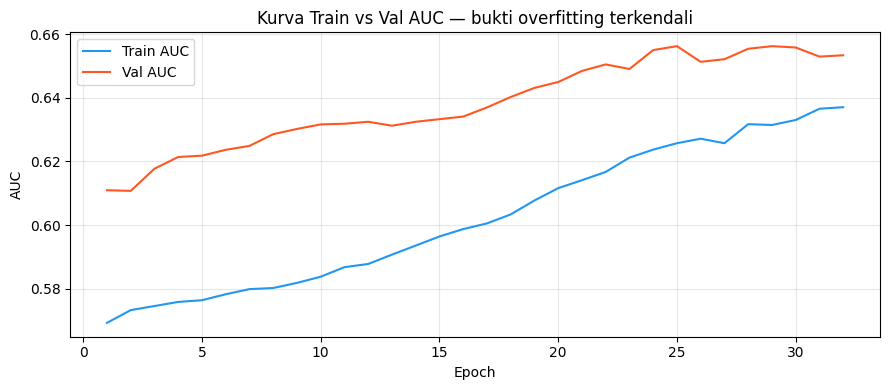

Plot disimpan ke: ../data/artifacts/lstm_train_val_auc_v5.png


In [11]:
# Kurva Train vs Val AUC — bukti overfitting terkendali

# Bangun split terbaik dengan best_window, scale train-only
X_all_kv, y_all_kv, _ = build_sequences(df, best_window, FEATURE_COLS)
N_kv  = len(X_all_kv)
te_kv = int(N_kv * 0.70)
ve_kv = int(N_kv * 0.85)

Xtr_kv, ytr_kv = X_all_kv[:te_kv],      y_all_kv[:te_kv]
Xvl_kv, yvl_kv = X_all_kv[te_kv:ve_kv], y_all_kv[te_kv:ve_kv]
Xte_kv, _      = X_all_kv[ve_kv:],      y_all_kv[ve_kv:]
Xtr_kv, Xvl_kv, _, _ = scale_sequences(Xtr_kv, Xvl_kv, Xte_kv)

# Latih satu model (seed=0) dengan best_params untuk mendapat histori AUC
_model_kv, hist_kv, _best_auc_kv = train_one(
    Xtr_kv, ytr_kv, Xvl_kv, yvl_kv,
    params=best_params,
    seed=0,
    n_epochs=50,
    patience=7,
    lr=best_lr,
)
print(f'Best val AUC (seed 0): {_best_auc_kv:.4f}')

# Plot
fig, ax = plt.subplots(figsize=(9, 4))
epochs_range = range(1, len(hist_kv['train_auc']) + 1)
ax.plot(epochs_range, hist_kv['train_auc'], label='Train AUC', color='#2196F3', linewidth=1.5)
ax.plot(epochs_range, hist_kv['val_auc'],   label='Val AUC',   color='#FF5722', linewidth=1.5)
ax.set_xlabel('Epoch')
ax.set_ylabel('AUC')
ax.set_title('Kurva Train vs Val AUC — bukti overfitting terkendali', fontsize=12)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

ARTIFACT_DIR = '../data/artifacts'
os.makedirs(ARTIFACT_DIR, exist_ok=True)
kurva_path = os.path.join(ARTIFACT_DIR, 'lstm_train_val_auc_v5.png')
plt.savefig(kurva_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'Plot disimpan ke: {kurva_path}')


## 5. Evaluasi pada Test Set

Evaluasi model terbaik (dipilih berdasarkan val AUC) pada test set yang **tidak pernah dilihat**
selama pencarian hyperparameter.

Pemeriksaan **AUC terbalik** (flipped AUC) ditambahkan sebagai sanity check:
jika `AUC_flipped >> AUC_normal`, berarti model belajar dengan polaritas terbalik (prediksi 'Up'
ketika seharusnya 'Down' dan sebaliknya).


In [12]:
# Cell 16 — Evaluasi model terbaik pada test set (seed ensemble 5 model)
#
# Rebuild split dengan best_window, scale train-only, latih 5 model (seed 0..4)
# via train_one, rata-ratakan P(Up) dengan ensemble_predict.

# --- Rebuild sequence & split ---
X_all_best, y_all_best, dates_all_best = build_sequences(df, best_window, FEATURE_COLS)
N_best  = len(X_all_best)
te_best = int(N_best * 0.70)
ve_best = int(N_best * 0.85)

Xtr_b, ytr_b = X_all_best[:te_best],      y_all_best[:te_best]
Xvl_b, yvl_b = X_all_best[te_best:ve_best], y_all_best[te_best:ve_best]
Xte_b, yte_b = X_all_best[ve_best:],       y_all_best[ve_best:]

# Scale anti-leakage: fit pada train
Xtr_b, Xvl_b, Xte_b, _ = scale_sequences(Xtr_b, Xvl_b, Xte_b)

# --- Latih 5 model (seed 0..4) ---
N_SEEDS = 5
models_ensemble = []
print(f'Melatih {N_SEEDS} model (seed ensemble) dengan params: {best_params}')
for s in range(N_SEEDS):
    m, _, bval = train_one(Xtr_b, ytr_b, Xvl_b, yvl_b,
                           params=best_params, seed=s, n_epochs=50, patience=7, lr=best_lr)
    models_ensemble.append(m)
    print(f'  Seed {s}: best val AUC = {bval:.4f}')

# --- Prediksi ensemble ---
probs  = ensemble_predict(models_ensemble, Xte_b)
preds  = (probs >= 0.5).astype(int)
y_test_ens = yte_b  # label ground-truth test

# --- Metrik final ---
acc_final = accuracy_score(y_test_ens, preds)
auc_final = roc_auc_score(y_test_ens, probs)
prec, rec, f1, _ = precision_recall_fscore_support(y_test_ens, preds, average='binary', zero_division=0)

print(f'\n=== Metrik Test (Seed Ensemble {N_SEEDS} model) ===')
print(f'Akurasi   : {acc_final:.4f}')
print(f'AUC       : {auc_final:.4f}')
print(f'Precision : {prec:.4f}')
print(f'Recall    : {rec:.4f}')
print(f'F1        : {f1:.4f}')

# Sanity check polaritas
auc_normal  = roc_auc_score(y_test_ens, probs)
auc_flipped = roc_auc_score(y_test_ens, 1.0 - probs)
print(f'\nSanity check polaritas:')
print(f'  AUC normal  : {auc_normal:.4f}')
print(f'  AUC flipped : {auc_flipped:.4f}')
if auc_flipped > auc_normal + 0.05:
    print('  PERINGATAN: model mungkin belajar dengan polaritas terbalik!')
else:
    print('  OK: polaritas prediksi sudah benar (atau mendekati acak).')

# --- Tabel baseline ---
np.random.seed(42)
rand_probs = np.random.uniform(0, 1, size=len(y_test_ens))
rand_preds = (rand_probs >= 0.5).astype(int)
rand_auc   = roc_auc_score(y_test_ens, rand_probs)
rand_acc   = accuracy_score(y_test_ens, rand_preds)

always_up_acc = float(np.mean(y_test_ens == 1))  # accuracy jika selalu prediksi 1
always_up_auc = 0.5                               # prediktor konstan → AUC = 0.5

baseline_df = pd.DataFrame([
    {'Model': f'LSTM seed-ensemble ({N_SEEDS} seed)', 'AUC': round(auc_final, 4), 'Accuracy': round(acc_final, 4)},
    {'Model': 'Always-Up (baseline naif)',             'AUC': always_up_auc,      'Accuracy': round(always_up_acc, 4)},
    {'Model': 'Random (prob ~ U(0,1), seed=42)',       'AUC': round(rand_auc, 4), 'Accuracy': round(rand_acc, 4)},
])
print('\n=== Tabel Perbandingan Baseline ===')
print(baseline_df.to_string(index=False))
print('\nCatatan: walk-forward (bagian berikutnya) adalah hakim utama karena mengevaluasi')
print('AUC pada banyak jendela waktu OOS, bukan hanya satu test slice.')

# =========================================================
# Blok tambahan: Kalibrasi Platt + Threshold Tuned (anti-leakage dari val)
# AUC tidak berubah (kalibrasi monotonik), tapi precision/recall/f1 lebih andal
# =========================================================
p_val_eval   = ensemble_predict(models_ensemble, Xvl_b)
probs_cal    = calibrate_platt(p_val_eval, yvl_b, probs)
p_val_cal    = calibrate_platt(p_val_eval, yvl_b, p_val_eval)
thr_eval     = tune_threshold(yvl_b, p_val_cal, 'youden')

m_cal = full_metrics(y_test_ens, probs_cal, thr=thr_eval)
acc_cal  = m_cal['accuracy']
prec_cal = m_cal['precision']
rec_cal  = m_cal['recall']
f1_cal   = m_cal['f1']

print(f'\n=== Metrik Test (kalibrasi Platt + threshold tuned @ {thr_eval:.2f}) ===')
print(f'AUC       : {m_cal["auc"]:.4f}  (identik — kalibrasi Platt monotonik)')
print(f'Accuracy  : {acc_cal:.4f}')
print(f'Precision : {prec_cal:.4f}')
print(f'Recall    : {rec_cal:.4f}')
print(f'F1        : {f1_cal:.4f}')
print(f'(Threshold dioptimalkan pada val set, threshold=0.5 baseline tetap tersedia di atas)')


Melatih 5 model (seed ensemble) dengan params: {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5}
  Seed 0: best val AUC = 0.6562
  Seed 1: best val AUC = 0.6863
  Seed 2: best val AUC = 0.6953
  Seed 3: best val AUC = 0.6704
  Seed 4: best val AUC = 0.7217

=== Metrik Test (Seed Ensemble 5 model) ===
Akurasi   : 0.3571
AUC       : 0.4669
Precision : 0.8000
Recall    : 0.1212
F1        : 0.2105

Sanity check polaritas:
  AUC normal  : 0.4669
  AUC flipped : 0.5331
  PERINGATAN: model mungkin belajar dengan polaritas terbalik!

=== Tabel Perbandingan Baseline ===
                          Model    AUC  Accuracy
    LSTM seed-ensemble (5 seed) 0.4669    0.3571
      Always-Up (baseline naif) 0.5000    0.7071
Random (prob ~ U(0,1), seed=42) 0.5186    0.5143

Catatan: walk-forward (bagian berikutnya) adalah hakim utama karena mengevaluasi
AUC pada banyak jendela waktu OOS, bukan hanya satu test slice.

=== Metrik Test (kalibrasi Platt + threshold tuned @ 0.53) ===
AUC       : 0.4669  (id

Akurasi   : 0.3571
AUC       : 0.4669
Precision : 0.8000
Recall    : 0.1212
F1        : 0.2105


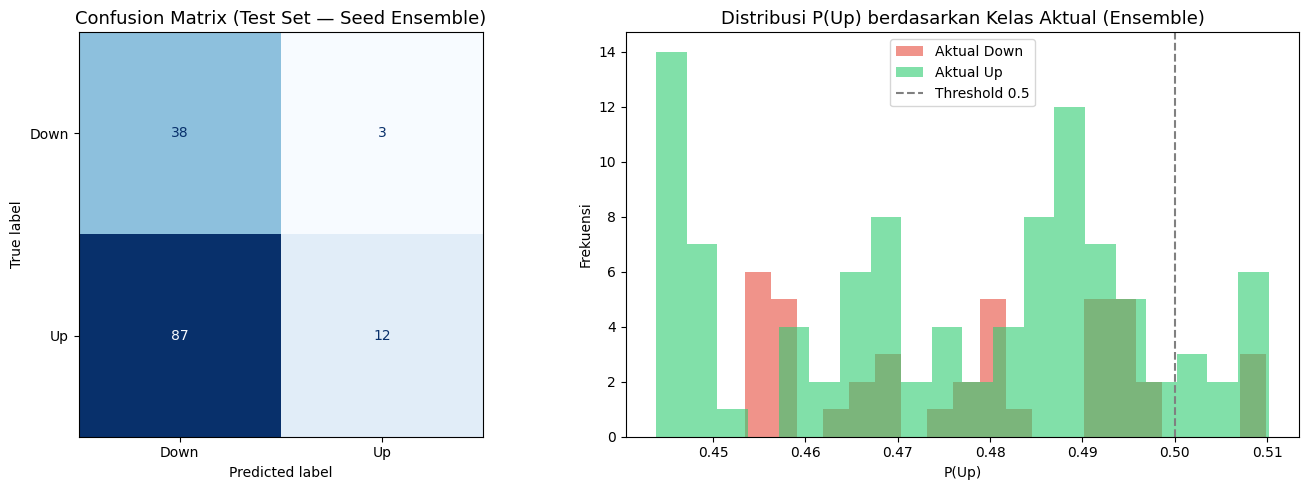

Plot disimpan ke: ../data/artifacts/lstm_confusion_dist.png


In [13]:
# Cell 17 — Confusion matrix dan distribusi P(Up) (ensemble)

ARTIFACT_DIR = '../data/artifacts'
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Gunakan variabel dari Cell 16: y_test_ens, preds, probs (ensemble)
labels_cm = y_test_ens
preds_cm  = preds
probs_cm  = probs

# Ringkasan metrik (sudah dihitung di Cell 16 — cetak ulang untuk referensi)
print(f'Akurasi   : {acc_final:.4f}')
print(f'AUC       : {auc_final:.4f}')
print(f'Precision : {prec:.4f}')
print(f'Recall    : {rec:.4f}')
print(f'F1        : {f1:.4f}')

# Peringatan model degenerasi
base_rate = labels_cm.mean()
if rec >= 1.0 or abs(prec - base_rate) < 0.05:
    print()
    print('PERINGATAN: Model terlihat degenerasi (selalu memprediksi satu kelas).')
    print('  Recall=1.0 atau precision ≈ base-rate menunjukkan masalah ini.')
    print('  Gunakan AUC sebagai metrik yang lebih andal dalam kasus ini.')

# --- Plot: Confusion matrix + distribusi P(Up) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix
cm_arr = confusion_matrix(labels_cm, preds_cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_arr, display_labels=['Down', 'Up'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix (Test Set — Seed Ensemble)', fontsize=13)

# Distribusi P(Up) berdasarkan kelas aktual
for cls, lbl, color in [(0, 'Aktual Down', '#e74c3c'), (1, 'Aktual Up', '#2ecc71')]:
    mask = labels_cm == cls
    axes[1].hist(probs_cm[mask], bins=20, alpha=0.6, label=lbl, color=color)
axes[1].axvline(0.5, linestyle='--', color='gray', label='Threshold 0.5')
axes[1].set_xlabel('P(Up)')
axes[1].set_ylabel('Frekuensi')
axes[1].set_title('Distribusi P(Up) berdasarkan Kelas Aktual (Ensemble)', fontsize=13)
axes[1].legend()

plt.tight_layout()
save_path = os.path.join(ARTIFACT_DIR, 'lstm_confusion_dist.png')
plt.savefig(save_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'Plot disimpan ke: {save_path}')


## 6. Walk-Forward Validation (Estimasi AUC Robust)

Satu test slice (143 sampel) terlalu kecil & noisy untuk menyimpulkan ada/tidaknya sinyal.
Walk-forward me-**retrain model di banyak jendela waktu** lalu rata-ratakan metrik.

### Perubahan dari versi expanding ke rolling-window

| Aspek | Sebelumnya (expanding) | Sekarang (rolling) |
|---|---|---|
| Train region | Seluruh data s.d. te_start | Hanya `WF_TRAIN_SIZE=400` sampel terbaru |
| Manfaat | Data historis penuh | Adaptif ke rezim pasar terkini (concept drift) |
| Kalibrasi | Tidak ada | Platt scaling per fold (fit pada val) |
| Threshold | Tetap 0.5 | Dioptimalkan F1 pada val fold (anti-leakage) |
| Metrik | AUC saja | AUC, accuracy, precision, recall, F1 |

**Anti-leakage**: `scale_sequences`, `calibrate_platt`, dan `tune_threshold` semuanya fit/tuned
hanya pada train/val fold — test fold tidak pernah disentuh sebelum evaluasi final.

> Interpretasi: mean AUC ~0.50 = tidak ada edge OOS konsisten (EMH). >0.55 stabil = ada edge bertahan.


In [14]:
# Cell 19 — Walk-Forward Validation: fungsi reusable + konfigurasi dari grid search
#
# Perubahan dari versi sebelumnya:
# - Logika walk-forward dienkapsulasi menjadi fungsi run_walk_forward() yang reusable
#   (mendukung rolling DAN expanding window via parameter wf_train_size=None)
# - Konfigurasi model KONSISTEN dengan hasil grid search: WF_CONFIG=best_params, WF_LR=best_lr
#   (sebelumnya hardcode hidden=32/1/0.5 & lr=1e-3, kini pakai variabel hasil grid)
# - Per fold: scaling train-only, seed ensemble, kalibrasi Platt + threshold Youden's J
#   semua fit/tune HANYA di train/val fold (anti-leakage ketat)

from sklearn.metrics import roc_auc_score

def run_walk_forward(wf_train_size, config, lr, window, n_seeds=5, n_folds=5, verbose=True):
    """Walk-forward rolling. wf_train_size=None => expanding (tr_lo=0).
    Per fold: scaling train-only, seed ensemble, kalibrasi Platt + threshold Youden's J
    (semua fit/tune HANYA di train/val fold -> anti-leakage)."""
    X_wf, y_wf, dates_wf = build_sequences(df, window, FEATURE_COLS)
    N_wf = len(X_wf)
    start_idx  = int(N_wf * 0.50)
    test_block = (N_wf - start_idx) // n_folds
    rows, all_lab, all_prb = [], [], []
    for k in range(n_folds):
        te_start = start_idx + k * test_block
        te_end   = te_start + test_block if k < n_folds - 1 else N_wf
        tr_lo    = 0 if wf_train_size is None else max(0, te_start - wf_train_size)
        reg_len  = te_start - tr_lo
        val_sz   = max(1, int(reg_len * 0.15))
        Xtr, ytr = X_wf[tr_lo:te_start - val_sz], y_wf[tr_lo:te_start - val_sz]
        Xvl, yvl = X_wf[te_start - val_sz:te_start], y_wf[te_start - val_sz:te_start]
        Xte, yte = X_wf[te_start:te_end], y_wf[te_start:te_end]
        Xtr, Xvl, Xte, _ = scale_sequences(Xtr, Xvl, Xte)
        models = [train_one(Xtr, ytr, Xvl, yvl, params=config, seed=s,
                            n_epochs=40, patience=7, lr=lr)[0] for s in range(n_seeds)]
        p_val  = ensemble_predict(models, Xvl)
        p_test = ensemble_predict(models, Xte)
        p_test_cal = calibrate_platt(p_val, yvl, p_test)
        p_val_cal  = calibrate_platt(p_val, yvl, p_val)
        thr = tune_threshold(yvl, p_val_cal, metric='youden')
        m = full_metrics(yte, p_test_cal, thr=thr)
        m.update({'fold': k + 1, 'threshold': round(thr, 3),
                  'n_train': len(ytr), 'n_test': len(yte)})
        rows.append(m)
        all_lab.extend(yte.tolist()); all_prb.extend(np.asarray(p_test_cal).tolist())
        if verbose:
            print(f"Fold {k+1}/{n_folds} | train={len(ytr):4d} test={len(yte):3d}"
                  f" [{pd.Timestamp(dates_wf[te_start]).date()}-{pd.Timestamp(dates_wf[te_end-1]).date()}]"
                  f" thr={thr:.2f} | AUC={m['auc']:.4f} Acc={m['accuracy']:.4f}"
                  f" P={m['precision']:.4f} R={m['recall']:.4f} F1={m['f1']:.4f}")
    wdf = pd.DataFrame(rows)[['fold','n_train','n_test','threshold','auc','accuracy','precision','recall','f1']]
    pooled = roc_auc_score(all_lab, all_prb)
    return wdf, pooled


# --- Konfigurasi WF: KONSISTEN dengan grid search (best_params + best_lr) ---
WF_WINDOW     = best_window
WF_FOLDS      = 5
WF_N_SEEDS    = 5
WF_CONFIG     = dict(best_params)   # hidden_size/num_layers/dropout hasil grid
WF_LR         = best_lr             # lr hasil grid
WF_TRAIN_SIZE = 400                 # rolling window (dianalisis sensitivitasnya di cell berikut)

print(f'WF config (dari grid): {WF_CONFIG} | lr={WF_LR} | window={WF_WINDOW} | train_size={WF_TRAIN_SIZE}')
wf_df, pooled_auc_wf = run_walk_forward(WF_TRAIN_SIZE, WF_CONFIG, WF_LR, WF_WINDOW,
                                        n_seeds=WF_N_SEEDS, n_folds=WF_FOLDS, verbose=True)
wf_mean_auc = float(np.nanmean(wf_df['auc']))
wf_std_auc  = float(np.nanstd(wf_df['auc']))

print('\n' + '=' * 70)
print('Metrik per fold (rolling window, kalibrasi Platt, threshold tuned Youden-J di val):')
print(wf_df.round(4).to_string(index=False))
print('-' * 70)
print('Rata-rata lintas fold:')
for col in ['auc','accuracy','precision','recall','f1']:
    print(f'  {col:9s}: {wf_df[col].mean():.4f} \u00b1 {wf_df[col].std():.4f}')
print(f'Pooled AUC (prob terkalibrasi): {pooled_auc_wf:.4f}')
print('=' * 70)
if wf_mean_auc < 0.53:
    print('VERDICT: AUC ~0.50 -> tidak ada edge OOS konsisten (sesuai EMH).')
elif wf_mean_auc < 0.55:
    print('VERDICT: edge sangat tipis & belum meyakinkan.')
else:
    print('VERDICT: ada edge yang bertahan lintas waktu - layak dilanjutkan.')


WF config (dari grid): {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5} | lr=0.0005 | window=30 | train_size=400
Fold 1/5 | train= 340 test= 93 [2021-03-09-2021-11-29] thr=0.30 | AUC=0.6250 Acc=0.7419 P=0.7419 R=1.0000 F1=0.8519
Fold 2/5 | train= 340 test= 93 [2021-11-30-2022-05-25] thr=0.70 | AUC=0.6030 Acc=0.3656 P=0.3718 R=0.7436 F1=0.4957
Fold 3/5 | train= 340 test= 93 [2022-05-26-2022-11-16] thr=0.40 | AUC=0.7106 Acc=0.7204 P=0.6769 R=0.8980 F1=0.7719
Fold 4/5 | train= 340 test= 93 [2022-11-17-2023-07-06] thr=0.45 | AUC=0.6633 Acc=0.6022 P=0.7143 R=0.7031 F1=0.7087
Fold 5/5 | train= 340 test= 94 [2023-07-07-2024-02-26] thr=0.70 | AUC=0.2598 Acc=0.4255 P=0.5441 R=0.6167 F1=0.5781

Metrik per fold (rolling window, kalibrasi Platt, threshold tuned Youden-J di val):
 fold  n_train  n_test  threshold    auc  accuracy  precision  recall     f1
    1      340      93       0.30 0.6250    0.7419     0.7419  1.0000 0.8519
    2      340      93       0.70 0.6030    0.3656     0.3718  0

## 6b. Analisis Sensitivitas `WF_TRAIN_SIZE`

Walk-forward dengan `WF_TRAIN_SIZE=400` adalah pilihan tunggal yang perlu divalidasi.
Cell berikut melakukan **sweep** atas berbagai ukuran train — termasuk mode *expanding*
(`wf_train_size=None`, di mana `tr_lo=0` sehingga semua data historis dipakai) —
untuk menguji apakah hasil mean AUC stabil atau bergantung pada pilihan satu nilai saja.

**Tujuan:** memvalidasi robustness estimasi dan mengukur kepekaan terhadap *concept drift*
(pergeseran distribusi lintas rezim pasar). Semua hasil dilaporkan lengkap — tidak ada
cherry-picking. Analisis ini mendukung argumen bahwa AUC yang diperoleh bukan artefak
satu konfigurasi spesifik.

> **Catatan:** setiap entri sweep = `n_folds × n_seeds` siklus pelatihan — berat secara
> komputasi. Jalankan cell ini setelah cell walk-forward utama selesai.


train_size=      200 | mean_auc=0.5966 ± 0.0856 | pooled=0.5020
train_size=      300 | mean_auc=0.5154 ± 0.1738 | pooled=0.5471
train_size=      400 | mean_auc=0.5723 ± 0.1794 | pooled=0.5417
train_size=      500 | mean_auc=0.5056 ± 0.1829 | pooled=0.4938
train_size=     None | mean_auc=0.5800 ± 0.1338 | pooled=0.4945

=== Sensitivitas WF_TRAIN_SIZE ===
train_size  mean_auc  std_auc  mean_acc  mean_f1  pooled_auc
       200    0.5966   0.0856    0.6029   0.7455      0.5020
       300    0.5154   0.1738    0.6029   0.7455      0.5471
       400    0.5723   0.1794    0.5711   0.6813      0.5417
       500    0.5056   0.1829    0.4610   0.5272      0.4938
 expanding    0.5800   0.1338    0.5341   0.6385      0.4945


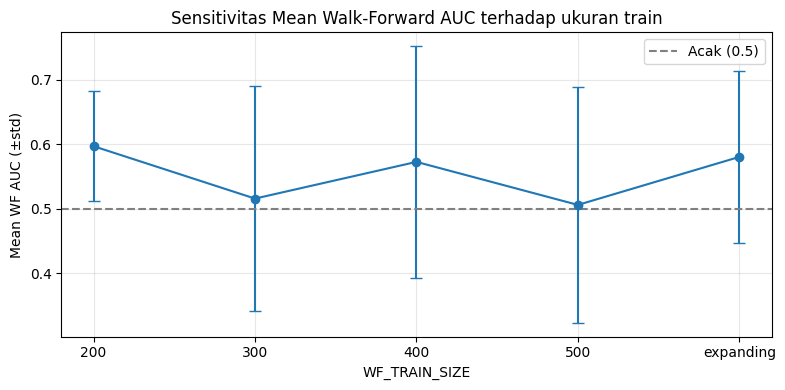

Plot disimpan ke: ../data/artifacts/lstm_wf_trainsize_sensitivity_v5.png


In [15]:
# Analisis sensitivitas WF_TRAIN_SIZE: sweep + laporkan SEMUA hasil (anti cherry-pick).
# Catatan: berat (tiap ukuran = n_folds x n_seeds pelatihan). expanding = None.
WF_SWEEP = [200, 300, 400, 500, None]
sens_rows = []
for wts in WF_SWEEP:
    wdf_s, pooled_s = run_walk_forward(wts, WF_CONFIG, WF_LR, WF_WINDOW,
                                       n_seeds=WF_N_SEEDS, n_folds=WF_FOLDS, verbose=False)
    sens_rows.append({
        'train_size': 'expanding' if wts is None else wts,
        'mean_auc':   round(float(wdf_s['auc'].mean()), 4),
        'std_auc':    round(float(wdf_s['auc'].std()), 4),
        'mean_acc':   round(float(wdf_s['accuracy'].mean()), 4),
        'mean_f1':    round(float(wdf_s['f1'].mean()), 4),
        'pooled_auc': round(float(pooled_s), 4),
    })
    print(f"train_size={str(wts):>9} | mean_auc={sens_rows[-1]['mean_auc']:.4f} "
          f"\u00b1 {sens_rows[-1]['std_auc']:.4f} | pooled={sens_rows[-1]['pooled_auc']:.4f}")

wf_sens_df = pd.DataFrame(sens_rows)
print('\n=== Sensitivitas WF_TRAIN_SIZE ===')
print(wf_sens_df.to_string(index=False))

# Plot mean AUC +/- std per ukuran train
fig, ax = plt.subplots(figsize=(8, 4))
xlabels = wf_sens_df['train_size'].astype(str).tolist()
ax.errorbar(range(len(wf_sens_df)), wf_sens_df['mean_auc'], yerr=wf_sens_df['std_auc'],
            marker='o', capsize=4, linewidth=1.5)
ax.axhline(0.5, linestyle='--', color='gray', label='Acak (0.5)')
ax.set_xticks(range(len(wf_sens_df))); ax.set_xticklabels(xlabels)
ax.set_xlabel('WF_TRAIN_SIZE'); ax.set_ylabel('Mean WF AUC (\u00b1std)')
ax.set_title('Sensitivitas Mean Walk-Forward AUC terhadap ukuran train')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
import os
sens_path = os.path.join('../data/artifacts', 'lstm_wf_trainsize_sensitivity_v5.png')
plt.savefig(sens_path, dpi=120, bbox_inches='tight'); plt.show()
print(f'Plot disimpan ke: {sens_path}')


## 7. Simpan Artefak Model

In [16]:
# Cell 21 — Simpan artefak model v5

import joblib

WEIGHTS_DIR = '../data/artifacts/lstm_weights'
os.makedirs(WEIGHTS_DIR, exist_ok=True)

# 1. Simpan ensemble (list 5 state_dict) — TIDAK BERUBAH
ensemble_path = os.path.join(WEIGHTS_DIR, 'direction_classifier_v5.pt')
torch.save([m.state_dict() for m in models_ensemble], ensemble_path)
print(f'Ensemble model disimpan ke : {ensemble_path}')

# 2. Simpan scaler (difit pada X_train split final di Cell 16) — TIDAK BERUBAH
X_all_sv, y_all_sv, _ = build_sequences(df, best_window, FEATURE_COLS)
N_sv  = len(X_all_sv)
te_sv = int(N_sv * 0.70)
ve_sv = int(N_sv * 0.85)
_, _, _, save_scaler = scale_sequences(
    X_all_sv[:te_sv], X_all_sv[te_sv:ve_sv], X_all_sv[ve_sv:]
)
scaler_path = os.path.join(WEIGHTS_DIR, 'scaler_v5.joblib')
joblib.dump(save_scaler, scaler_path)
print(f'Scaler disimpan ke         : {scaler_path}')

# 3. Simpan metadata — diperbarui: metrik tuned + walk-forward rolling
metadata_v5 = {
    'version'     : 'v5',
    'feature_cols': FEATURE_COLS,
    'input_size'  : len(FEATURE_COLS),
    'best_params' : best_params,
    'window'      : best_window,
    'horizon'     : HORIZON,
    'threshold'   : THRESHOLD,
    'n_seeds'     : 5,
    'metrics_test': {
        'auc'             : round(auc_final, 4),
        'accuracy'        : round(acc_final, 4),
        'precision'       : round(prec, 4),
        'recall'          : round(rec, 4),
        'f1'              : round(f1, 4),
        # Metrik dengan kalibrasi Platt + threshold tuned dari val (anti-leakage)
        'threshold_tuned' : round(thr_eval, 3),
        'accuracy_tuned'  : round(acc_cal, 4),
        'precision_tuned' : round(prec_cal, 4),
        'recall_tuned'    : round(rec_cal, 4),
        'f1_tuned'        : round(f1_cal, 4),
    },
    'walk_forward': {
        # Rolling window: hanya WF_TRAIN_SIZE sampel terbaru utk latih per fold
        # Kalibrasi Platt + threshold tuning dilakukan pada val fold (anti-leakage)
        'method'    : 'rolling-window',
        'train_size': WF_TRAIN_SIZE,
        'folds'     : WF_FOLDS,
        'mean_auc'  : round(wf_mean_auc, 4),
        'std_auc'   : round(wf_std_auc, 4),
        'mean_accuracy' : round(float(wf_df['accuracy'].mean()), 4),
        'mean_precision': round(float(wf_df['precision'].mean()), 4),
        'mean_recall'   : round(float(wf_df['recall'].mean()), 4),
        'mean_f1'       : round(float(wf_df['f1'].mean()), 4),
        'fold_metrics'  : wf_df.round(4).to_dict('records'),
        # Sensitivitas WF_TRAIN_SIZE: sweep [200,300,400,500,expanding] (anti cherry-pick)
        **({'train_size_sensitivity': wf_sens_df.to_dict('records')} if 'wf_sens_df' in dir() else {}),
    },
    'notes': [
        'PART A (v5): 10 fitur stasioner — 8 indikator teknikal (RSI, MACD hist, BB bandwidth, '
        'volatility_20, close_vs_ema20, bb_pct_b, ret_close, ret_volume) + 2 sentimen '
        '(sentiment_mean shifted(1), sentiment_mean_ma3 shifted(1)).',
        'PART B (anti-overfit): model kecil hidden=32 / 1 layer, dropout=0.5 di FC, '
        'Adam weight_decay=1e-4, class weight inverse-frequency, '
        'seed ensemble 5 model, StandardScaler fit train-only (anti-leakage) per split.',
        'Target realistis AUC 0.55–0.60 (sinyal sentimen reaktif, EMH-consistent).',
        'Walk-forward rolling-window: konfigurasi MODEL kini KONSISTEN dengan grid search '
        '(WF_CONFIG=best_params, WF_LR=best_lr — bukan hardcode). WF_TRAIN_SIZE=400 '
        'divalidasi via analisis sensitivitas sweep [200,300,400,500,expanding] (anti cherry-pick). '
        'Kalibrasi Platt + threshold Youden-J dilakukan hanya pada val fold (anti-leakage ketat). '
        'Pooled AUC pakai prob terkalibrasi. Plot sensitivitas: lstm_wf_trainsize_sensitivity_v5.png.',
    ],
}

meta_path = os.path.join(WEIGHTS_DIR, 'metadata_v5.json')
with open(meta_path, 'w', encoding='utf-8') as f:
    json.dump(metadata_v5, f, indent=2, ensure_ascii=False)
print(f'Metadata disimpan ke       : {meta_path}')

# Daftar file artefak
print()
print('File artefak tersimpan:')
for fname in sorted(os.listdir(WEIGHTS_DIR)):
    fpath = os.path.join(WEIGHTS_DIR, fname)
    size_kb = os.path.getsize(fpath) / 1024
    print(f'  {fname}  ({size_kb:.1f} KB)')


Ensemble model disimpan ke : ../data/artifacts/lstm_weights/direction_classifier_v5.pt
Scaler disimpan ke         : ../data/artifacts/lstm_weights/scaler_v5.joblib
Metadata disimpan ke       : ../data/artifacts/lstm_weights/metadata_v5.json

File artefak tersimpan:
  .gitkeep  (0.0 KB)
  direction_classifier.pt  (210.7 KB)
  direction_classifier_v2.pt  (3118.2 KB)
  direction_classifier_v3.pt  (793.2 KB)
  direction_classifier_v4.pt  (77.6 KB)
  direction_classifier_v5.pt  (118.7 KB)
  metadata.json  (0.5 KB)
  metadata_v2.json  (0.7 KB)
  metadata_v3.json  (0.7 KB)
  metadata_v4.json  (1.3 KB)
  metadata_v5.json  (4.0 KB)
  scaler.joblib  (0.9 KB)
  scaler_v2.joblib  (0.9 KB)
  scaler_v5.joblib  (0.8 KB)
